In [2]:
import importlib

import PINN_utils
from PINN_utils import *

In [2]:
importlib.reload(PINN_utils)
from PINN_utils import *

In [5]:
def visualiza_solucao(path):
    ts, xs, sol = get_reference_sol(path)

    # contours = plt.contour(*np.meshgrid(ts, xs), sol.T, 5, colors='black')
    # plt.clabel(contours, inline=1, fontsize=10)
    plt.imshow(sol.T, cmap="viridis", origin='lower', extent=[ts[0], ts[-1], xs[0], xs[-1]], aspect="auto")
    plt.xlabel('t')
    plt.ylabel('x')
    plt.colorbar(label='S(x, t) (ref)')
    plt.show()

In [60]:
pde = PDE(lambda x: torch.where(x >= 0, torch.clamp(0.9 - 2.0 * x, max=0.9, min=0.2), 0.9))

In [19]:
xs = torch.linspace(0.0, 1.0, 500)
Ss = torch.linspace(pde.S_wc, 1.0 - pde.S_gr, 500)
S0s = pde.S0(xs)
fs = pde.f(Ss)

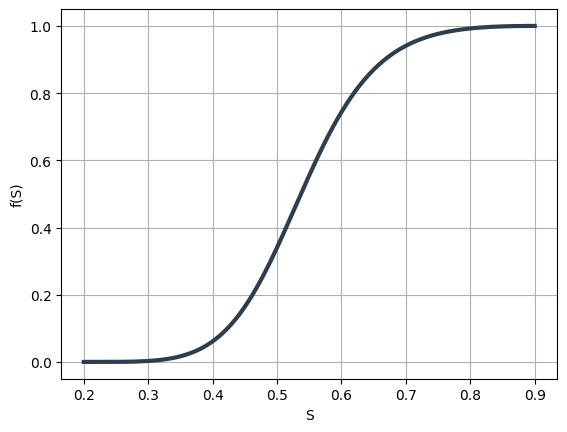

In [98]:
plt.plot(Ss, fs, c="#2C3E50", linewidth=3)
plt.xlabel("S")
plt.ylabel("f(S)")
plt.grid(True)
plt.show()

0.5286871261610204
0.5286871261610204
0.5286871261610204


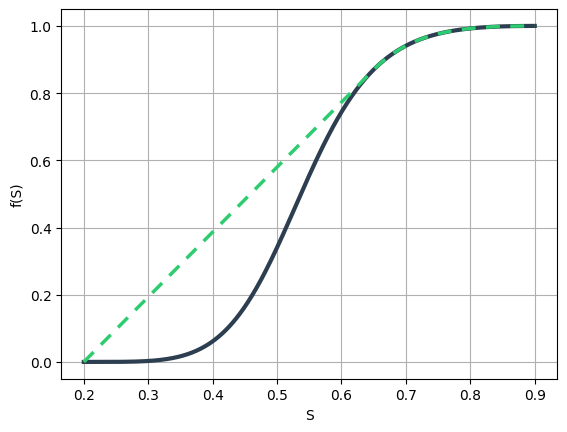

In [103]:
s = (pde.f(pde.get_S_R(Ss[0])) - pde.f(Ss[0])) / (pde.get_S_R(Ss[0]) - Ss[0])
line = torch.where(Ss <= pde.get_S_R(Ss[0]), fs[0] + s * (Ss - Ss[0]), pde.f(Ss))

plt.plot(Ss, fs, c="#2C3E50", linewidth=3)
plt.plot(Ss, line, c="#2ECC71", linestyle="--", dashes=(4, 3), linewidth=2.5)
plt.xlabel("S")
plt.ylabel("f(S)")
plt.grid(True)
plt.show()

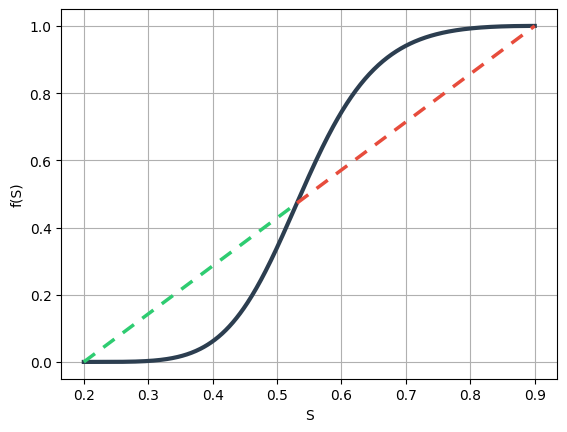

In [109]:
s = (pde.f(Ss[-1]) - pde.f(Ss[0])) / (Ss[-1] - Ss[0])
line = fs[0] + s * (Ss - Ss[0])
mask = line > fs - 1e-10 # add eps so endpoints are not included

plt.plot(Ss, fs, c="#2C3E50", linewidth=3)
plt.plot(Ss[mask], line[mask], c="#2ECC71", linestyle="--", dashes=(4, 3), linewidth=2.5)
plt.plot(Ss[~mask], line[~mask], c="#E74C3C", linestyle="--", dashes=(4, 3), linewidth=2.5)
plt.xlabel("S")
plt.ylabel("f(S)")
plt.grid(True)
plt.show()

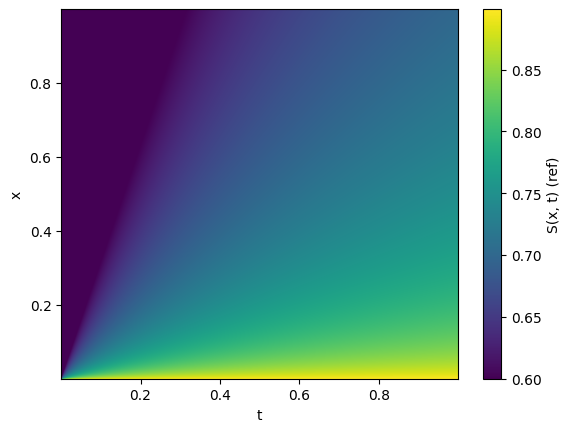

In [30]:
visualiza_solucao("referencias/caso3.txt") # dt: 0.000114533

In [7]:
# latex de cada termo
L_PDE = r"\mathcal{L}_{PDE}"
L_IC = r"\mathcal{L}_{IC}"
L_BC = r"\mathcal{L}_{BC}"
L_IM = r"\mathcal{L}_{IM}"
L_C = r"\mathcal{L}_{C}"
L_R = r"\mathcal{L}_{R}"
L_T = r"\mathcal{L}_{T}"

In [8]:
def compara_ref_result(ref_path, result_path, pde, metricas, is_psnn=True, x0=0.0, t0=0.0, X_b=0.0):
    ref_ts, ref_xs, ref_sol = get_reference_sol(ref_path)
    if is_psnn:
        model = RHPiecewise_PINN.load(result_path)
    else:
        model = PINN.load(result_path)

    pontos_colocacao = torch.stack([
        torch.from_numpy(ref_ts).repeat_interleave(len(ref_xs)),
        torch.from_numpy(ref_xs).repeat(len(ref_ts))
    ], dim=1).to(torch.float32).requires_grad_(True)
    pontos_IC = torch.stack([torch.zeros(ref_xs.shape), torch.from_numpy(ref_xs)], dim=1).to(torch.float32).requires_grad_(True)
    pontos_BC = torch.stack([torch.from_numpy(ref_ts), torch.zeros(ref_ts.shape)], dim=1).to(torch.float32).requires_grad_(True)
    
    colocacao_sol = model(pontos_colocacao)
    IC_sol = model(pontos_IC)
    BC_sol = model(pontos_BC)

    if is_psnn:
        pontos_interface = torch.from_numpy(ref_ts).reshape((-1, 1)).to(torch.float32).requires_grad_(True)
        descontinuidade = model.get_discontinuity(pontos_interface)
        mask_domain = ((descontinuidade > np.min(ref_xs)) & (descontinuidade < np.max(ref_xs))).flatten()
        mask_shock = mask_domain & (pontos_interface < t0).flatten()
        pontos_descontinuidade = torch.column_stack((pontos_interface[mask_domain], descontinuidade[mask_domain]))
        

    funcoes = {
        L_PDE: pde.pde_loss,
        L_IC: pde.IC_loss,
        L_BC: pde.BC_loss,
        L_IM: pde.IM_loss,
        L_C: pde.continuity_loss,
        L_R: pde.RH_loss,
        L_T: pde.Welge_loss,
    }
    pesos = {
        L_PDE: 1,
        L_IC: 10,
        L_BC: 10,
        L_IM: 5,
        L_C: 5,
        L_R: 1,
        L_T: 1,
    }
    
    valores = { r"\mathcal{L}": 0 }
    for metrica in metricas:
        if metrica in [L_PDE, L_IM]:
            valores[metrica] = funcoes[metrica](pontos_colocacao, colocacao_sol).item()
        elif metrica == L_IC:
            valores[metrica] = funcoes[metrica](pontos_IC, IC_sol).item()
        elif metrica == L_BC:
            valores[metrica] = funcoes[metrica](pontos_BC, BC_sol).item()
        elif metrica == L_C:
            valores[metrica] = funcoes[metrica](pontos_interface, descontinuidade, mask_shock, model.net_IC, model.net_BC).item()
        elif metrica == L_R:
            valores[metrica] = funcoes[metrica](pontos_interface, descontinuidade, mask_domain, model.net_IC, model.net_BC, t0, X_b).item()
        elif metrica == L_T:
            valores[metrica] = funcoes[metrica](pontos_descontinuidade, model.net_IC, model.net_BC).item()

        valores[r"\mathcal{L}"] += pesos[metrica] * valores[metrica]

    return valores, np.mean((ref_sol - colocacao_sol.detach().cpu().numpy().reshape((len(ref_ts), len(ref_xs)))) ** 2)
    

In [9]:
def resultados_para_latex(
    valores,
    mse=None,
    caption="",
    label="",
    metricas=None,
    precision=2
):
    nomes = {
        r"\mathcal{L}_{PDE}": r"\mathcal{L}_{PDE}",
        r"\mathcal{L}_{IC}": r"\mathcal{L}_{IC}",
        r"\mathcal{L}_{BC}": r"\mathcal{L}_{BC}",
        r"\mathcal{L}_{IM}": r"\mathcal{L}_{IM}",
        r"\mathcal{L}_{C}": r"\mathcal{L}_{C}",
        r"\mathcal{L}_{R}": r"\mathcal{L}_{R}",
        r"\mathcal{L}_{T}": r"\mathcal{L}_{T}",
        r"\mathcal{L}": r"\mathcal{L}",
    }

    if metricas is None:
        metricas = list(valores.keys())

    # First column is reserved for the row label
    colunas = [nomes[m] for m in metricas]

    if mse is not None:
        colunas.append(r"\text{MSE}")

    n_colunas = len(colunas) + 1
    formato = "|"+ "c|" * (n_colunas - 1)

    tabela = [
        r"\begin{table}[ht]",
        r"\centering",
    ]

    if caption:
        tabela.append(r"\caption{" + caption + "}")

    if label:
        tabela.append(r"\label{" + label + "}")

    tabela.extend([
        r"\resizebox{\textwidth}{!}{",
        r"\begin{tabular}{" + formato + r"}",
        r"\hline",
        " & ".join([f"${c}$" for c in colunas]) + r" \\",
        r"\hline",
    ])

    def formatar(valor):
        return rf"\np{{{valor:.{precision}e}}}"

    linha = [formatar(valores[m]) for m in metricas]

    if mse is not None:
        linha.append(formatar(mse))

    tabela.extend([
        " & ".join(linha) + r" \\",
        r"\hline",
        r"\end{tabular}",
        r"}",
        r"\end{table}",
    ])

    return "\n".join(tabela)

In [139]:
# pde = PDE(lambda x: 0.6, S_injecao=0.9)
pde = PDE(lambda x: torch.clamp(0.9 - torch.sin(2.5 * x) * 0.7, max=0.9, min=0.2))

In [142]:
valores, mse = compara_ref_result("referencias/ref1.txt", "resultados/prob4.pth", pde, [L_PDE, L_IC, L_BC, L_IM, L_C, L_R], is_psnn=True,
                                 t0=pde.get_breaking_time(torch.linspace(0.0, 1.0, 500)), X_b=pde.get_shock_characteristic_start(torch.linspace(0.0, 1.0, 500)))

In [143]:
print(resultados_para_latex(valores, mse))

\begin{table}[ht]
\centering
\resizebox{\textwidth}{!}{
\begin{tabular}{|c|c|c|c|c|c|c|c|}
\hline
$\mathcal{L}$ & $\mathcal{L}_{PDE}$ & $\mathcal{L}_{IC}$ & $\mathcal{L}_{BC}$ & $\mathcal{L}_{IM}$ & $\mathcal{L}_{C}$ & $\mathcal{L}_{R}$ & $\text{MSE}$ \\
\hline
\np{5.41e-03} & \np{2.60e-04} & \np{2.14e-05} & \np{1.97e-07} & \np{1.51e-05} & \np{2.60e-04} & \np{3.55e-03} & \np{9.40e-05} \\
\hline
\end{tabular}
}
\end{table}


In [3]:
def graficos_solucao(ref_path, result_path, is_psnn=True, n_plots=4, ncols=2):
    ref_ts, ref_xs, ref_sol = get_reference_sol(ref_path)
    if is_psnn:
        model = RHPiecewise_PINN.load(result_path)
    else:
        model = PINN.load(result_path)
        
    pontos_colocacao = torch.stack([
        torch.from_numpy(ref_ts).repeat_interleave(len(ref_xs)),
        torch.from_numpy(ref_xs).repeat(len(ref_ts))
    ], dim=1).to(torch.float32)
    colocacao_sol = model(pontos_colocacao).detach().cpu().numpy().reshape((len(ref_ts), len(ref_xs)))
    
    error = np.abs(ref_sol - colocacao_sol)

    # Plot
    fig1, ax1 = plt.subplots(figsize=(6, 5), constrained_layout=True)
    extent = [ref_ts.min(), ref_ts.max(), ref_xs.min(), ref_xs.max()]

    # Predicted solution
    im0 = ax1.imshow(colocacao_sol.T, extent=extent, origin="lower", aspect="auto", cmap="viridis")
    ax1.set_title("Solução Predita")
    ax1.set_xlabel(r"$t$")
    ax1.set_ylabel(r"$x$")
    ax1.axis(extent)

    fig1.colorbar(im0, ax=ax1, label=r"$S(x,t)$")

    if is_psnn:
        # plota posição do choque
        shock_pos = model.get_discontinuity(torch.tensor(ref_ts, dtype=torch.float32).reshape((-1, 1))).detach()
        ax1.plot(ref_ts, shock_pos, c="r", linestyle="--", label="rede de detecção do choque")
        ax1.legend()
    

    # Squared error
    fig2, ax2 = plt.subplots(figsize=(6, 5), constrained_layout=True)
    im1 = ax2.imshow(error.T, extent=extent, origin="lower", aspect="auto", cmap="magma", vmin=0, vmax=np.percentile(error, 99))
    ax2.set_title("Erro Absoluto")
    ax2.set_xlabel(r"$t$")
    ax2.set_ylabel(r"$x$")
    ax2.axis(extent)

    fig2.colorbar(im1, ax=ax2, label=r"$|S_{\mathrm{ref}}-S_{\mathrm{pred}}|$")
    

    step = max(1, len(ref_ts) // (n_plots + 1))
    indices = np.linspace(0, len(ref_ts) - 1, n_plots + 2, dtype=int)[1:-1]

    nrows = int(np.ceil(n_plots / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 3.5 * nrows), sharex=True, sharey=True, constrained_layout=True)
    axes = np.asarray(axes).flatten()


    for ax, idx in zip(axes, indices):
        t = ref_ts[idx]

        with torch.no_grad():
            X = torch.tensor(np.stack([np.full(ref_xs.shape, t), ref_xs], axis=1), dtype=torch.float32)
            S = model(X).cpu().numpy().flatten()

        ax.plot(ref_xs, ref_sol[idx], color="gray", linewidth=2, label="Referência")
        ax.plot(ref_xs, S, color="black", linestyle="--", linewidth=1.8, label="PINN")

        ax.set_title(rf"$t={t:.2f}$")
        ax.grid(alpha=0.3)
        ax.set_xlabel(r"$x$")
        ax.set_ylabel(r"$S(x,t)$")

    for ax in axes[n_plots:]:
        ax.remove()

    # Shared legend
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper center", ncol=2, frameon=False)

    return fig1, fig2, fig, axes[:n_plots]

    

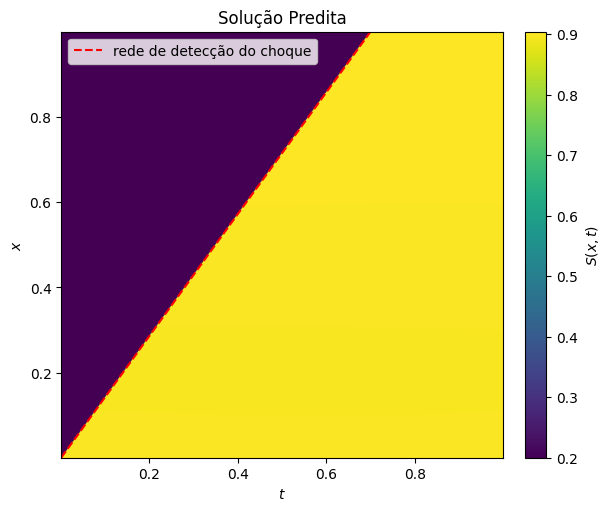

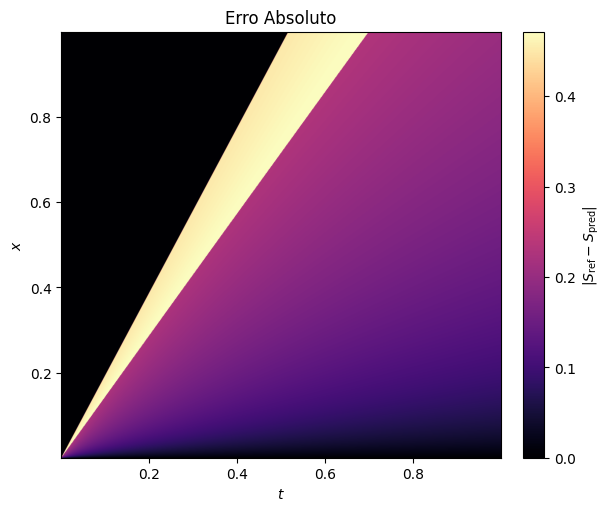

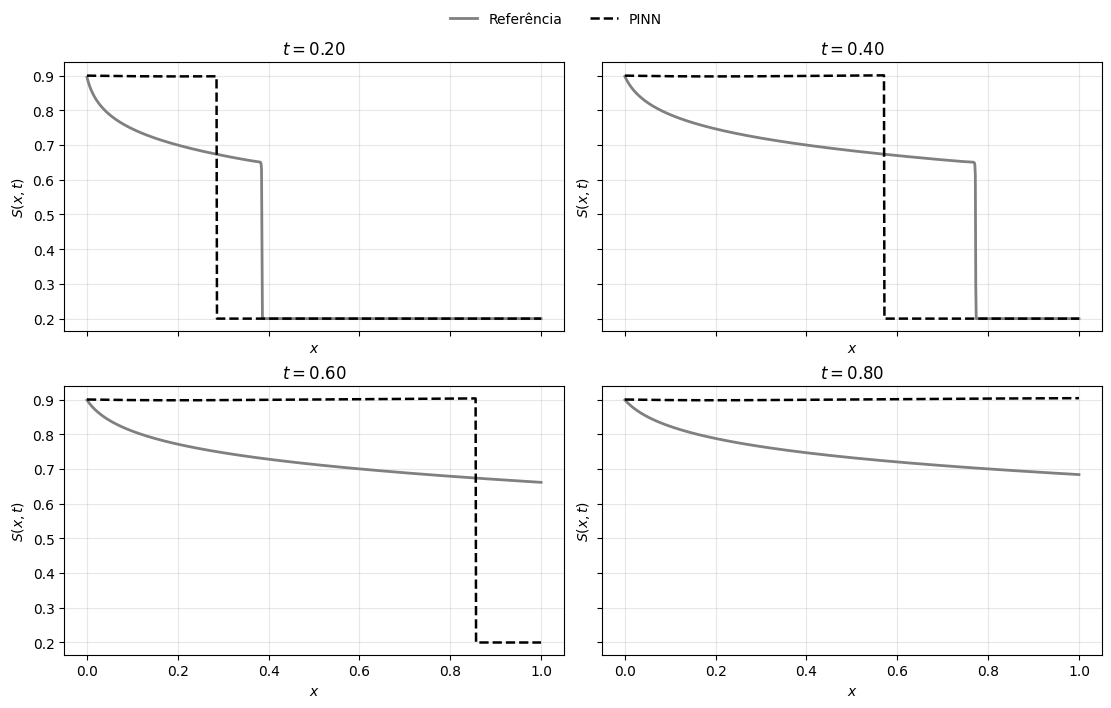

In [10]:
fig1, fig2, fig, axes = graficos_solucao("referencias/caso2.txt", "resultados/prob2__sem_T.pth", is_psnn=True)